In [258]:
import numpy as np

In [273]:
S0 = 100.0
K = 1.2
r = 0.02
sigma = 0.25
T = 2
J = 24

In [274]:
def generate_brownian(N, T):
    G = np.random.normal(0, 1, N)
    step = T/N
    increment = np.sqrt(step) * G
    brownian = np.concatenate(([0.0], np.cumsum(increment)))
    return brownian


In [275]:
def simulate_trajectory(S0, J, r, sigma, T):
    traj = [S0]
    step = T/J
    W = generate_brownian(J, T)
    for i in range(1,J+1):
        S_i = traj[i-1]*np.exp((r - (sigma*sigma)/2 )* step + sigma*(W[i]-W[i-1]))
        traj.append(S_i)
    return traj

In [276]:
def compute_payoff(traj, K):
    S_max = np.max(traj)
    S_T = traj[-1]
    return max(S_max - K * S_T, 0.0)

In [277]:
def monte_carlo_standard(M, S0, J, r, sigma, T, K):
    sum = 0.0
    s_sum = 0.0
    for _ in range(M):
        traj = simulate_trajectory(S0, J, r, sigma, T)
        result = compute_payoff(traj, K)
        sum += result
        s_sum += result*result
    mean = sum/M
    discount_factor = np.exp(-r*T)
    price = mean * discount_factor

    var = (1/M * s_sum - mean*mean) * discount_factor*discount_factor
    half_ci = 2.0*np.sqrt(var/M)
    # print("var = ", var)
    # print("[", (price - half_ci), " , ", (price + half_ci),"]")
    return price, half_ci

In [264]:
monte_carlo_standard(50000, S0, J, r, sigma, T, K)

(np.float64(11.49953572844249), np.float64(0.134094666672246))

In [265]:
def simulate_antithetic_trajectory(S0, J, r, sigma, T):
    traj = [S0]
    traj_anti = [S0]
    step = T/J
    W = generate_brownian(J, T)
    W_anti = - W
    for i in range(1,J+1):
        S_i = traj[i-1]*np.exp((r - (sigma*sigma)/2 )* step + sigma*(W[i]-W[i-1]))
        traj.append(S_i)

        S_i_anti = traj_anti[i-1]*np.exp((r - (sigma*sigma)/2 )* step + sigma*(W_anti[i]-W_anti[i-1]))
        traj_anti.append(S_i_anti)

    return traj, traj_anti

In [266]:
def monte_carlo_antithetic(M, S0, J, r, sigma, T, K):
    sum = 0.0
    s_sum = 0.0
    for _ in range(M):
        traj, traj_anti = simulate_antithetic_trajectory(S0, J, r, sigma, T)
        result = (compute_payoff(traj, K) + compute_payoff(traj_anti, K)) / 2
        sum += result
        s_sum += result*result
    mean = sum/M
    discount_factor = np.exp(-r*T)
    price = mean * discount_factor
    var = (1/M * s_sum - mean*mean) * discount_factor*discount_factor
    half_ci = 2.0*np.sqrt(var/M)
    # print("[", (price - half_ci), " , ", (price + half_ci),"]")
    # print("var = ", var)
    return price, half_ci

In [267]:
monte_carlo_antithetic(50000, S0, J, r, sigma, T, K)

(np.float64(11.500098402202761), np.float64(0.06676629216187306))

In [268]:
def compute_optimal_lambda(M, X, Y):
    return (X*Y)/Y*Y

In [269]:
def monte_carlo_controle_variate(M, S0, J, r, sigma, T, K):
    sum_result = 0.0
    sum_result_times_variate = 0.0
    sum_variate_sq = 0.0
    sum_variate = 0.0
    sum_result_sq = 0.0

    factor = np.exp(r*T)
    for _ in range(M):
        traj = simulate_trajectory(S0, J, r, sigma, T)
        result = compute_payoff(traj, K)
        variate =  - (traj[-1] - traj[0] * factor)
        sum_result += result
        sum_result_sq += result * result
        sum_result_times_variate += result*variate
        sum_variate += variate
        sum_variate_sq += variate*variate

    lam = sum_result_times_variate / sum_variate_sq
    mean = 1/M * (sum_result -  sum_variate * lam)
    discount_factor = np.exp(-r*T)
    price = mean * discount_factor

    var_result = (1/M * sum_result_sq - mean*mean) * discount_factor * discount_factor

    var = var_result - 2 * lam * (sum_result_times_variate/M) * discount_factor + lam*lam*(sum_variate_sq/M)
    half_ci = 2.0*np.sqrt(var/M)
    # print("[", (price - half_ci), " , ", (price + half_ci),"]")
    # print("var = ", var)
    return price, half_ci

In [270]:
monte_carlo_controle_variate(50000, S0, J, r, sigma, T, K)

(np.float64(11.528858312608579), np.float64(0.10391224191414299))

In [271]:
def monte_carlo_controle_variate_better(M, S0, J, r, sigma, T, K):
    X = []
    Y = []
    factor = np.exp(r*T)

    for _ in range(M):
        traj = simulate_trajectory(S0, J, r, sigma, T)
        result = compute_payoff(traj, K)
        X.append(result)
        variate =  - (traj[-1] - traj[0] * factor)
        Y.append(variate)
    X = np.array(X)
    Y = np.array(Y)
    lam = np.dot(X, Y) / np.dot(Y,Y)

    discount_factor = np.exp(-r*T)
    Z = (X - lam * Y ) * discount_factor
    
    mean_Z = np.mean(Z)
    var_z = np.var(Z)

    price = mean_Z

    half_ci = 2.0*np.sqrt(var_z/M)
    # print("[", (price - half_ci), " , ", (price + half_ci),"]")
    # print("var = ", var_z)
    return price, half_ci

In [272]:
monte_carlo_controle_variate_better(50000, S0, J, r, sigma, T, K)

(np.float64(11.518801849847437), np.float64(0.10380578927874895))

In [292]:
import matplotlib.pyplot as plt
M=50000
K = np.linspace(0.8, 1.2, 10)
prices_standard = []
prices_antithetic = []
prices_control = []
ci_standard = []
ci_antithetic = []
ci_control = []
for k in K:
    std = monte_carlo_standard(M, S0, J, r, sigma, T, k)
    anti = monte_carlo_antithetic(M, S0, J, r, sigma, T, k)
    control = monte_carlo_controle_variate_better(M, S0, J, r, sigma, T, k)
    prices_standard.append(std[0])
    prices_antithetic.append(anti[0])
    prices_control.append(control[0])
    ci_standard.append(std[1])
    ci_antithetic.append(anti[1])
    ci_control.append(control[1])


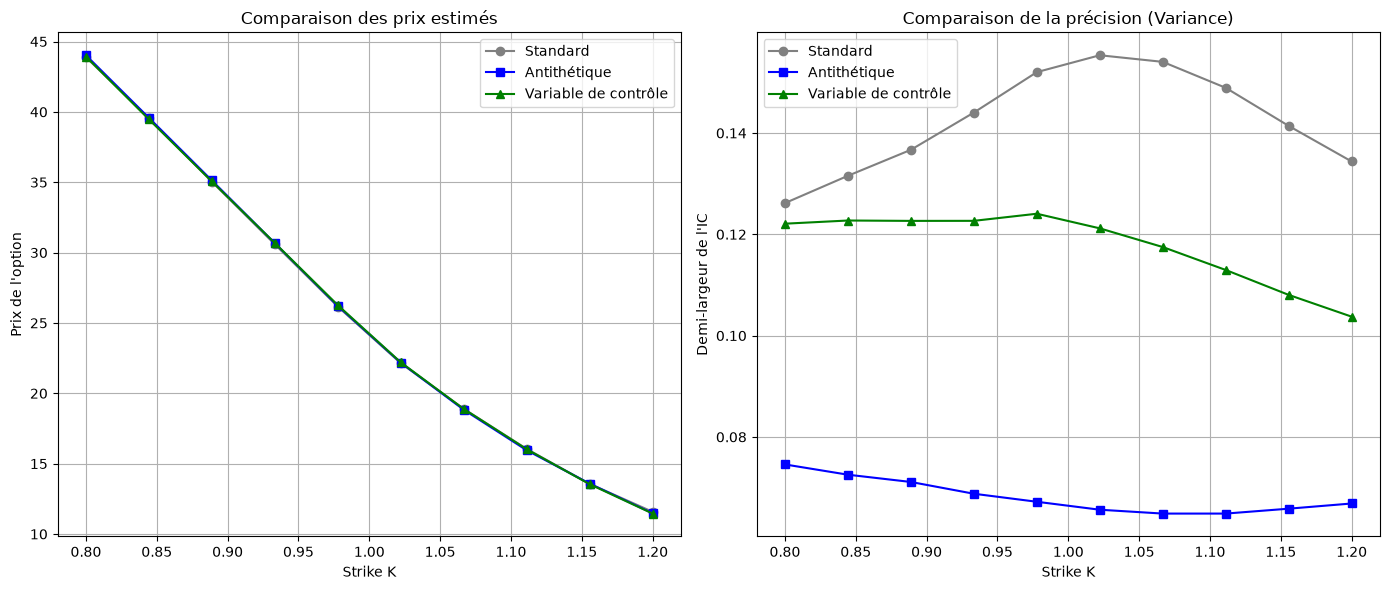

In [293]:
fig, (ax1, ax2)= plt.subplots(1,2, figsize=(14, 6))

ax1.plot(K, prices_standard, 'o-', label='Standard', color='gray')
ax1.plot(K, prices_antithetic, 's-', label='Antithétique', color='blue')
ax1.plot(K, prices_control, '^-', label='Variable de contrôle', color='green')
ax1.set_xlabel("Strike K")
ax1.set_ylabel("Prix de l'option")
ax1.set_title("Comparaison des prix estimés")
ax1.legend()
ax1.grid(True)

ax2.plot(K, ci_standard, 'o-', label='Standard', color='gray')
ax2.plot(K, ci_antithetic, 's-', label='Antithétique', color='blue')
ax2.plot(K, ci_control, '^-', label='Variable de contrôle', color='green')
ax2.set_xlabel("Strike K")
ax2.set_ylabel("Demi-largeur de l'IC")
ax2.set_title("Comparaison de la précision (Variance)")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

## Exercise 2 : Importance Sampling

In [175]:
import numpy as np
from scipy.stats import norm

In [176]:
# params:
S0 = 100.0
r = 0.03
sigma = 0.2
T = 2
K = 120.0

In [203]:
d1 = (np.log(S0/K) + (r+sigma*sigma*0.5)*T)/(sigma*np.sqrt(T))
d2 = d1 - sigma*np.sqrt(T)
theoretical_price = S0*norm.cdf(d1) - K*norm.cdf(d2)*np.exp(-r*T)

In [235]:
def psi(g):
    return np.exp(-r*T) * np.maximum(S0*np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*g) - K, 0.0)

In [236]:
def U(theta, g):
    return (theta-g) * (psi(g)**2) * np.exp(-theta*g + 0.5 * theta**2)

In [237]:
theta0 = 0.0
beta = 0.75
def gamma_n(n,gamma):
    return gamma/((n+500))**beta

def theta(n,gamma, alpha=1):
    tab = [0]*n
    if n==0:
        return [theta0]
    tab = [0.0]*n
    theta_prev = theta0
    for i in range(n):
        mid = theta_prev - gamma_n(i, gamma)* U(theta_prev, np.random.normal(0,1))
        mid_sq = mid*mid
        if mid_sq <= np.log(alpha+1):
            tab[i] = mid
        else:
            alpha+=1
            tab[i] = theta0
        theta_prev = tab[i]
    return tab
    

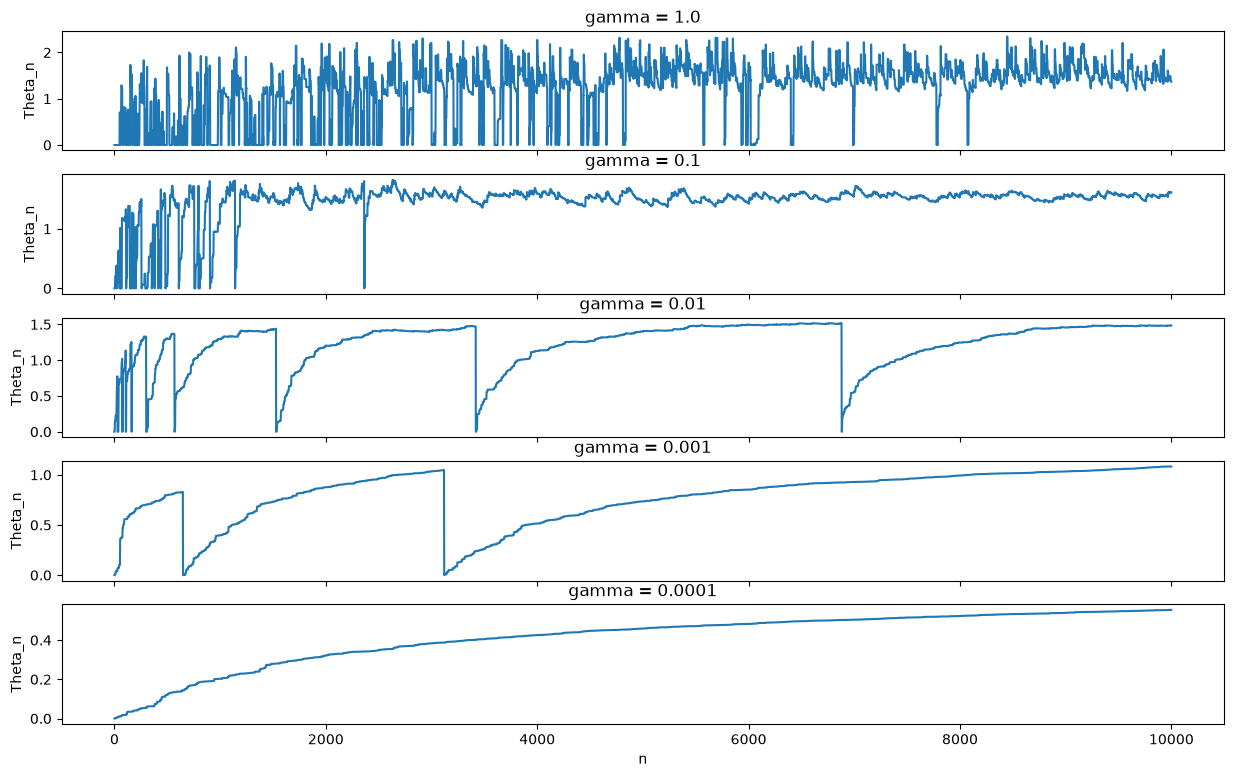

In [238]:
N = 10000
gamma_vals = [1.0, 0.1, 0.01, 0.001, 0.0001]
import matplotlib.pyplot as plt
fig, axes = plt.subplots(len(gamma_vals), sharex=True, figsize=(15,9))
plt.xlabel("n")
for i, gamma in enumerate(gamma_vals):
    axes[i].plot(range(N), theta(N, gamma))
    axes[i].set_ylabel(f'Theta_n')
    axes[i].set_title(f'gamma = {gamma}')

In [239]:
M = 100000
theta_hat = theta(N, 0.1)[-1]
def monte_carlo_importance_sampling(theta_hat):
    X=[]
    G = np.random.normal(0,1,M)
    for i in range(M):
        result = psi(G[i]+theta_hat) * np.exp(-theta_hat*G[i] - 0.5*theta_hat*theta_hat)
        X.append(result)
    X = np.array(X)
    print(f' mean = {np.mean(X)} , std = {np.std(X)}, IC = {1.96*np.std(X)/np.sqrt(M)}')

monte_carlo_importance_sampling(theta_hat)

 mean = 6.5422544111390994 , std = 4.065956349369053, IC = 0.02520105854442588


In [240]:
def monte_carlo_classic():
    G = np.random.normal(0,1,M)
    X = [psi(g) for g in G]
    print(f' mean = {np.mean(X)} , std = {np.std(X)}, IC = {1.96*np.std(X)/np.sqrt(M)}')
monte_carlo_classic()

 mean = 6.531769739456533 , std = 15.388478189701036, IC = 0.09537877597442865


In [241]:
def monte_carlo_antithetic():
    G = np.random.normal(0,1,M)
    G_anti = -G
    X = []
    for i in range(M):
        X.append((psi(G[i])+psi(G_anti[i]))/2)
    X = np.array(X)
    print(f' mean = {np.mean(X)} , std = {np.std(X)}, IC = {1.96*np.std(X)/np.sqrt(M)}')
monte_carlo_antithetic()

 mean = 6.574724115198254 , std = 9.885858342997903, IC = 0.06127318481971686


In [242]:
def monte_carlo_importance_sampling_unbiased():
    theta_tab = theta(N, 0.1)
    theta_mean = np.mean(theta_tab)
    X=[]
    G = np.random.normal(0,1,M)
    for i in range(M):
        result = psi(G[i]+theta_mean) * np.exp(-theta_mean*G[i] - 0.5*theta_mean*theta_mean)
        X.append(result)
    X = np.array(X)
    print(f' mean = {np.mean(X)} , std = {np.std(X)}, IC = {1.96*np.std(X)/np.sqrt(M)}')
monte_carlo_importance_sampling_unbiased()

 mean = 6.565223756762794 , std = 4.035177084623149, IC = 0.02501028668507322


In [243]:
def plot_monte_carlo_classic(i):
    G = np.random.normal(0,1,i)
    X = [psi(g) for g in G]
    return np.mean(X)

def plot_monte_carlo_ic_unbiased(i):
    theta_tab = theta(N, 0.01)
    theta_mean = np.mean(theta_tab)
    X=[]
    G = np.random.normal(0,1,M)
    for i in range(M):
        result = psi(G[i]+theta_mean) * np.exp(-theta_mean*G[i] - 0.5*theta_mean*theta_mean)
        X.append(result)
    X = np.array(X)
    return np.mean(X)

def plot_monte_carlo_ic(i):
    X=[]
    G = np.random.normal(0,1,M)
    for i in range(M):
        result = psi(G[i]+theta_hat) * np.exp(-theta_hat*G[i] - 0.5*theta_hat*theta_hat)
        X.append(result)
    X = np.array(X)
    return np.mean(X)

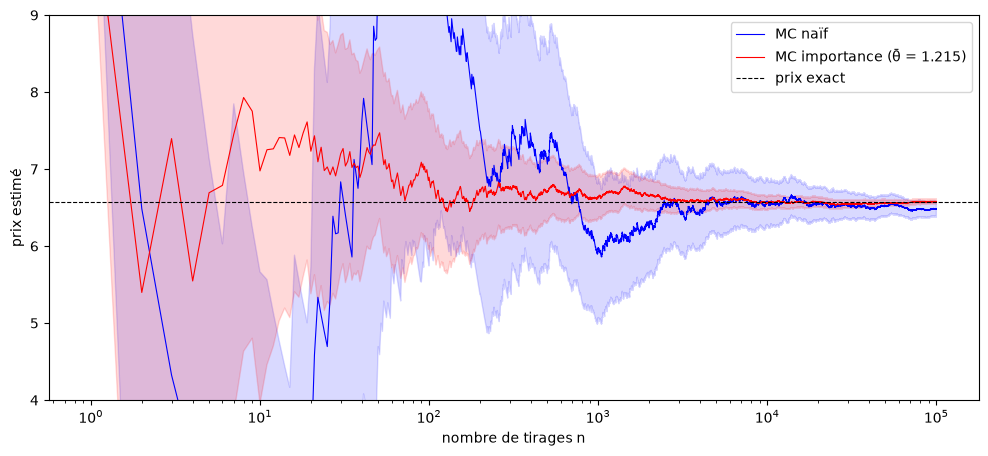

In [244]:
M = 100_000
N = 10_000

def poids_is(G, th):
    return psi(G + th) * np.exp(-th*G - 0.5*th**2)

def courbe(X):
    n = np.arange(1, len(X) + 1)
    moy = np.cumsum(X) / n
    var = np.cumsum(X**2)/n - moy**2
    return n, moy, 1.96*np.sqrt(np.maximum(var, 0)/n)

theta_bar = np.mean(theta(N, 0.01))          # appris UNE seule fois
G1, G2 = np.random.normal(0, 1, M), np.random.normal(0, 1, M)
X_mc = psi(G1)
X_is = poids_is(G2, theta_bar)

fig, ax = plt.subplots(figsize=(12, 5))
for X, lab, c in [(X_mc, "MC naïf", "blue"),
                  (X_is, f"MC importance (θ̄ = {theta_bar:.3f})", "red")]:
    n, moy, ic = courbe(X)
    ax.plot(n, moy, color=c, lw=0.8, label=lab)
    ax.fill_between(n, moy - ic, moy + ic, color=c, alpha=0.15)
ax.axhline(theoretical_price, ls="--", color="k", lw=0.8, label="prix exact")
ax.set_xscale("log"); ax.set_ylim(4, 9)
ax.set_xlabel("nombre de tirages n"); ax.set_ylabel("prix estimé"); ax.legend()
plt.show()